# 04 · Anomaly detection

The detector in this notebook **does not see the events calendar**. It monitors ~50 daily metrics across the whole
purchase life cycle, flags statistically unusual days, groups them into incidents, and only then compares the result
with `events_calendar.csv` and `promotions.csv` to (a) explain each incident and (b) measure how well detection works.

1. Metric panel and detector
2. Detected incidents vs the calendar (recall, unexplained flags)
3. Drill-downs that turn a flag into an explanation
4. Entity-level scan (a defective product) and level-shift detection

In [1]:
import sys, warnings
sys.path.insert(0, "../src"); sys.path.insert(0, "src")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from shopstats import *
set_style()
pd.options.display.float_format = "{:,.4f}".format
pd.set_option("display.width", 250, "display.max_columns", 40, "display.max_colwidth", 90, "display.max_rows", 200)
try:
    display
except NameError:
    display = print

ca = pd.read_parquet(OUT / "cube_all_incl_bots.parquet")
cc = pd.read_parquet(OUT / "cube_day_category_device.parquet")
O = load_orders()
I = pd.read_parquet(DATA / "order_items.parquet")
P = pd.read_parquet(DATA / "products.parquet")
S = load_sessions(["session_start", "device", "entered_payment", "purchased", "payment_method"])
EV, PR = load_events()
idx = np.arange(D)

## 1. Metric panel
Counts and values are monitored on a log scale, rates on a logit scale, so that deviations are relative and comparable.

In [2]:
M = {}      # name -> dict(group, kind, v (transformed), raw, n)
def add_count(name, group, x):
    x = np.asarray(x, float)
    M[name] = dict(group=group, kind="count", raw=x, v=np.where(x > 0, np.log(np.where(x > 0, x, 1)), np.nan), n=None)
def add_rate(name, group, k, n):
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = (k + 0.5) / (n + 1)
    p = np.clip(p, 1e-6, 1 - 1e-6)
    M[name] = dict(group=group, kind="rate", raw=np.where(n > 0, k / np.where(n > 0, n, 1), np.nan),
                   v=np.where(n >= 30, np.log(p / (1 - p)), np.nan), n=n, p=p)

tot = ca.groupby("day")[STAGES + ["bounce0"]].sum().reindex(idx)
add_count("sessions", "traffic", tot["sessions"])
for ch, x in ca.pivot_table(index="day", columns="channel", values="sessions", aggfunc="sum", observed=True).reindex(idx).items():
    add_count(f"sessions · {ch}", "traffic", x)
add_rate("zero-engagement share", "traffic", tot["bounce0"], tot["sessions"])
add_rate("conversion (visit→purchase)", "funnel", tot["purchased"], tot["sessions"])
gd = ca.groupby(["day", "device"], observed=True)[STAGES].sum().unstack().reindex(idx)
for dev in ["desktop", "mobile", "tablet"]:
    for prev, cur, name in zip(STAGES[:-1], STAGES[1:], STEP_NAMES):
        add_rate(f"{name} · {dev}", "funnel", gd[(cur, dev)], gd[(prev, dev)])
gc = cc.groupby(["day", "viewed_category"], observed=True)[["viewed_product", "added_to_cart"]].sum().unstack().reindex(idx).fillna(0)
for cat in gc["viewed_product"].columns:
    add_rate(f"view→cart · {cat}", "category", gc[("added_to_cart", cat)], gc[("viewed_product", cat)])
    add_count(f"product views · {cat}", "category", gc[("viewed_product", cat)])
od = O.groupby("day").agg(orders=("order_id", "size"), revenue=("revenue", "sum"), units=("units", "sum"),
                          cancelled=("status", lambda s: (s == "cancelled").sum()),
                          returned=("status", lambda s: s.isin(["returned", "partially_returned"]).sum())).reindex(idx)
add_count("orders", "sales", od["orders"]); add_count("revenue", "sales", od["revenue"])
add_count("average order value", "sales", od["revenue"] / od["orders"])
add_count("units per order", "sales", od["units"] / od["orders"])
S["day"] = S["day"].astype("int16")
pm = S[S["entered_payment"]].groupby(["day", "payment_method"], observed=True)["purchased"].agg(["sum", "size"]).unstack().reindex(idx)
for m_ in pm["sum"].columns:
    add_rate(f"payment success · {m_}", "payment", pm[("sum", m_)], pm[("size", m_)])
add_rate("cancellation rate", "post-purchase", od["cancelled"], od["orders"])
add_rate("orders with a return", "post-purchase", od["returned"], od["orders"])
for lab, mask in (("DE", O["country"].eq("DE")), ("other countries", ~O["country"].eq("DE"))):
    g = O[mask].groupby("day").agg(dd=("delivery_days", "mean"), canc=("status", lambda s: (s == "cancelled").sum()), n=("order_id", "size")).reindex(idx)
    add_count(f"delivery days · {lab}", "post-purchase", g["dd"].astype(float))
    add_rate(f"cancellation rate · {lab}", "post-purchase", g["canc"], g["n"])
rt = O.groupby("day")["review_rating"].mean().reindex(idx).astype(float)
add_count("average review rating", "post-purchase", rt)
print(f"{len(M)} metrics × {D} days = {len(M) * D:,} metric-days monitored")
print(pd.Series({k: v["group"] for k, v in M.items()}).value_counts().to_string())

55 metrics × 730 days = 40,150 metric-days monitored
funnel           16
category         16
traffic           8
post-purchase     7
sales             4
payment           4


### Detector
For each metric and day *t*:

* **expected value** = median of the same weekday over the previous 6 weeks (robust to earlier anomalies and to weekly seasonality);
* **residual** = observed − expected (on the log / logit scale);
* **scale** = 1.4826 × MAD of the previous 56 residuals, never below the binomial sampling error for rates;
* **robust z** = residual / scale.

Three flagging rules, from sharp to sustained:

1. **spike**: |z| ≥ 5 on a single day;
2. **two-day**: |z| ≥ 3.5 on two consecutive days with the same sign;
3. **sustained**: the 5-day sum of z divided by √5 is ≥ 5 in absolute value (catches modest shifts that persist, such as a
   10% category promotion).

With ~35,000 metric-days, a plain 3-sigma rule would raise about 95 false alarms from noise alone; the thresholds are
chosen to keep expected noise flags to a handful (the Bonferroni cut-off for α = 0.05 over all metric-days is |z| ≈ 4.6).
A metric is only scored once it has 8 weeks of history, so the first scored day is 27 Dec 2024 and a newly launched
category is not scored during its first 12 weeks.

In [3]:
Z_HARD, Z_SOFT, Z_SUST, LAGS, WIN, WARMUP_NEW = 5.0, 3.5, 5.0, 6, 56, 84

def detect(m):
    v = m["v"].copy()
    first = np.flatnonzero(~np.isnan(v))
    if len(first) and first[0] > 0:
        v[first[0]:first[0] + WARMUP_NEW] = np.nan          # new entity (e.g. a category launched mid-period): warm-up
    lagm = np.full((LAGS, D), np.nan)
    for k in range(1, LAGS + 1):
        lagm[k - 1, 7 * k:] = v[:-7 * k]
    base = np.nanmedian(lagm, axis=0)
    base[np.isnan(lagm).sum(axis=0) > 2] = np.nan
    r = v - base
    rs = pd.Series(r)
    med = rs.rolling(WIN, min_periods=28).median().shift(1)
    mad = (rs - med).abs().rolling(WIN, min_periods=28).median().shift(1)
    scale = 1.4826 * mad.values
    if m["kind"] == "rate":
        se = np.sqrt(1 / (m["n"] * m["p"] * (1 - m["p"]))) * 1.15         # + uncertainty of the 6-point median baseline
        scale = np.fmax(scale, se)
    scale = np.where(np.isnan(mad.values), np.nan, np.fmax(scale, 0.01))     # no score until the scale has 4+ weeks of history
    z = r / scale
    with np.errstate(invalid="ignore"):
        hard = np.abs(z) >= Z_HARD
        soft = np.abs(z) >= Z_SOFT
    sgn = np.sign(z)
    pair = soft & np.roll(soft, 1) & (sgn == np.roll(sgn, 1))
    pair[0] = False
    z5 = pd.Series(z).rolling(5, min_periods=5).sum().values / np.sqrt(5)
    with np.errstate(invalid="ignore"):
        sust_end = np.abs(z5) >= Z_SUST
    sust = np.zeros(D, bool)
    for e_ in np.flatnonzero(sust_end):          # flag the days of the window that themselves deviate in that direction
        seg = z[e_ - 4:e_ + 1]
        sust[e_ - 4:e_ + 1] |= (np.sign(seg) == np.sign(z5[e_])) & (np.abs(seg) >= 2)
    flag = hard | pair | np.roll(pair, -1) | sust
    flag &= ~np.isnan(z)
    expected = np.exp(base) if m["kind"] == "count" else 1 / (1 + np.exp(-base))
    return z, flag, expected

rows = []
Zs = {}
for name, m in M.items():
    z, flag, exp_ = detect(m)
    Zs[name] = z
    for t in np.flatnonzero(flag):
        rows.append(dict(metric=name, group=m["group"], day=int(t), date=DAYS[t], observed=m["raw"][t], expected=exp_[t],
                         deviation=m["raw"][t] / exp_[t] - 1, z=z[t]))
A = pd.DataFrame(rows)
valid = int(sum(np.isfinite(z).sum() for z in Zs.values()))
allz = np.concatenate([z[np.isfinite(z)] for z in Zs.values()])
print(f"{len(A):,} flagged metric-days out of {valid:,} scored ({len(A) / valid:.2%}); "
      f"robust z has median {np.median(allz):+.2f} and IQR/1.349 = {np.subtract(*np.percentile(allz, [75, 25])) / 1.349:.2f} (≈1 if well calibrated)")

1,038 flagged metric-days out of 34,874 scored (2.98%); robust z has median +0.04 and IQR/1.349 = 0.91 (≈1 if well calibrated)


## 2. From flags to incidents, and what explains them
Flags on adjacent days (across all metrics) are merged into one incident. Only *now* is the calendar consulted. An
incident is "explained" by a calendar entry when two things hold:

* **timing** — it overlaps the entry (its first 14 days for long-running changes, when the detector can still see the
  onset), or the days right after it ends (pull-forward after a promotion; the return to normal also looks like an anomaly
  to a trailing baseline);
* **signature** — at least one of the incident's flagged metrics is of the kind that entry would plausibly move
  (a carrier strike can explain delivery times, not add-to-cart rates). Without this second condition, anything that
  happens to coincide with a long-running event would be "explained" by it.

In [4]:
SIGNATURE = {   # which metrics a calendar entry can plausibly move (regular expressions on metric names)
    "P01": "orders|revenue|sessions|view→cart|cart→checkout|conversion|units|average order", "P07": "orders|revenue|sessions|view→cart|cart→checkout|conversion|units|average order",
    "P02": "Fashion|Home & Garden|Email|orders|revenue", "P09": "Fashion|Home & Garden|Email|orders|revenue",
    "P03": "Fashion|Email|post-purchase:orders with a return", "P11": "Fashion|Email|orders with a return",
    "P04": "Electronics|Books|Email", "P12": "Electronics|Books|Email",
    "P05": "Email|conversion|orders|revenue|view→cart", "P06": "cart→checkout|orders|revenue|Email|conversion", "P10": "cart→checkout|orders|revenue|Email|conversion",
    "P08": "Beauty|units per order", "E01": "sessions|product views|orders|revenue",
    "E03": "Electronics|Paid Search", "E04": "payment→purchase · mobile|payment success|conversion|orders",
    "E06": "Social|visit→view|view→cart|conversion|sessions$", "E07": "Electronics|average order value",
    "E08": "view→cart|cart→checkout", "E09": "zero-engagement|Direct|visit→view · desktop|conversion|sessions$",
    "E10": "DE|cancellation|review|return", "E11": "Paid Search", "E15": "checkout→payment · mobile|payment→purchase · mobile",
    "E16": "payment success|payment→purchase", "E17": "Home & Garden",
    "E19": "Toys", "E20": "Toys", "E21": "Sports", "E22": "Sports", "E23": "delivery days", "E24": "delivery days",
}   # E02 loyalty, E12 macro (gradual), E05 new category (in warm-up), E13 one SKU, E14 / E18 experiments:
    # nothing in a daily panel is expected to move abruptly

cal = []
for _, p in PR.iterrows():
    cal.append(dict(id=p.promo_id, name=p["name"], origin="internal", kind="promotion", a=day_index(p.start_date), b=day_index(p.end_date)))
for _, e in EV.iterrows():
    cal.append(dict(id=e.event_id, name=e["name"], origin=e.origin, kind=e.type, a=day_index(e.start_date), b=min(day_index(e.end_date), D - 1)))
cal = pd.DataFrame(cal)
cal["b_seen"] = np.minimum(cal["b"], cal["a"] + 13)
cal["sig"] = cal["id"].map(SIGNATURE)
# every promotion is advertised, so it can also move store-wide traffic and the blended funnel / sales metrics
PROMO_GENERIC = "|sessions|product views|view→cart|conversion|orders|revenue|units per order|average order value"
cal.loc[cal["kind"].eq("promotion"), "sig"] = cal.loc[cal["kind"].eq("promotion"), "sig"] + PROMO_GENERIC
FIRST_SCORED = 56

import re
def explain_flag(t, metric):
    """calendar entries that can explain one flagged metric-day (timing AND signature)"""
    out = []
    for c in cal.itertuples():
        if not isinstance(c.sig, str) or not re.search(c.sig, metric):
            continue
        if c.a <= t <= c.b_seen + 1:
            out.append(f"{c.id} {c.name}")
        elif c.kind == "promotion" and c.b + 1 <= t <= c.b + 8:
            out.append(f"after {c.id} (pull-forward)")
        elif c.b < D - 1 and (c.b - c.a) >= 7 and c.b + 1 <= t <= c.b + 28:
            out.append(f"end of {c.id} {c.name}")
        elif c.kind != "promotion" and (c.b - c.a) < 7 and c.b + 1 <= t <= c.b + 4:
            out.append(f"after {c.id}")
    return out

A["why"] = [explain_flag(t, m_) for t, m_ in zip(A["day"], A["metric"])]
A["explained"] = A["why"].map(len) > 0
print(f"flag level: {A['explained'].mean():.1%} of flagged metric-days are explained by a calendar entry with a matching signature; "
      f"{(~A['explained']).sum()} are not ({(~A['explained']).sum() / valid:.2%} of all scored metric-days)")

def explain(a, b, metrics):
    sub = A[A["day"].between(a, b)]
    seen = []
    for w_ in sub["why"]:
        for x in w_:
            if x not in seen:
                seen.append(x)
    return seen

days_f = np.sort(A["day"].unique())
groups, cur = [], [days_f[0]]
for d_ in days_f[1:]:
    if d_ - cur[-1] <= 1:
        cur.append(d_)
    else:
        groups.append(cur); cur = [d_]
groups.append(cur)
inc = []
A["incident"] = -1
for i, gdays in enumerate(groups):
    a, b = gdays[0], gdays[-1]
    sub = A[A["day"].between(a, b)]
    A.loc[sub.index, "incident"] = i
    top = sub.loc[sub["z"].abs().groupby(sub["metric"]).idxmax()].sort_values("z", key=np.abs, ascending=False)
    why = explain(a, b, sub["metric"].unique())
    inc.append(dict(incident=i, start=DAYS[a].date(), end=DAYS[b].date(), days=b - a + 1, flags=len(sub), unexplained_flags=int((~sub["explained"]).sum()),
                    metrics=sub["metric"].nunique(),
                    peak_z=top["z"].iloc[0], signature="; ".join(f"{r.metric} {r.deviation:+.0%}" for r in top.head(4).itertuples()),
                    explained_by=" | ".join(why) if why else "— unexplained —"))
INC = pd.DataFrame(inc)
A["explained_by"] = A["why"].map(lambda w_: " | ".join(w_) if w_ else "— unexplained —")
A.drop(columns=["day", "why"]).to_csv(OUT / "anomalies_flagged.csv", index=False)
INC.to_csv(OUT / "anomaly_incidents.csv", index=False)
unexpl = INC[INC["explained_by"].str.startswith("—")]
print(f"{len(INC)} incidents; {len(INC) - len(unexpl)} explained by the calendar, {len(unexpl)} with no explanation at all "
      f"(holding {unexpl['flags'].sum()} flags)")
display(INC.drop(columns="incident"))
print("\nUnexplained flags by metric (candidates for noise, or for something the calendar does not know about):")
display(A[~A["explained"]].groupby("metric").agg(flags=("z", "size"), max_abs_z=("z", lambda s: s.abs().max())).sort_values("flags", ascending=False).head(12))

flag level: 91.0% of flagged metric-days are explained by a calendar entry with a matching signature; 93 are not (0.27% of all scored metric-days)
28 incidents; 24 explained by the calendar, 4 with no explanation at all (holding 4 flags)


,start,end,days,flags,unexplained_flags,metrics,peak_z,signature,explained_by
0,2025-02-18,2025-02-18,1,9,0,9,-10.0360,product views · Electronics -31%; product views · Fashion -33%; product views · Beauty...,E01 Site outage (6 hours)
1,2025-03-20,2025-03-26,7,112,0,18,9.4903,product views · Electronics +39%; product views · Fashion +40%; product views · Home &...,P02 Spring Sale 2025
2,2025-04-01,2025-04-10,10,10,0,1,4.4451,product views · Sports & Outdoors +33%,after P02 (pull-forward) | E21 Spring sports season 2025
3,2025-04-12,2025-04-14,3,3,0,1,2.8491,product views · Sports & Outdoors +28%,E21 Spring sports season 2025
4,2025-04-16,2025-04-16,1,1,1,1,2.3194,product views · Sports & Outdoors +25%,— unexplained —
5,2025-05-05,2025-05-18,14,18,0,2,-4.7740,view→cart · Electronics -23%; sessions · Paid Search -20%,E03 Competitor electronics campaign
6,2025-05-20,2025-05-20,1,1,1,1,-2.4565,view→cart · Electronics -17%,— unexplained —
7,2025-06-10,2025-06-13,4,20,0,5,-9.4722,payment→purchase · mobile -44%; payment success · wallet -37%; payment success · card ...,E04 Mobile checkout bug
8,2025-07-01,2025-07-28,28,113,0,16,11.2715,view→cart · Fashion +35%; sessions · Email +48%; sessions · Social +32%; product views...,P03 Summer Clearance 2025 | after P03 (pull-forward) | end of E21 Spring sports season...
9,2025-08-05,2025-08-05,1,1,0,1,-3.0118,view→cart · Books & Media -16%,end of P03 Summer Clearance 2025



Unexplained flags by metric (candidates for noise, or for something the calendar does not know about):


,flags,max_abs_z
metric,,
product views · Electronics,13,4.1207
product views · Fashion,13,4.1973
view→cart · mobile,11,3.5195
view→cart · desktop,8,4.2478
product views · Books & Media,6,3.4354
sessions · Affiliate,6,3.6138
product views · Toys & Games,6,3.9210
sessions · Paid Search,6,2.6307
revenue,5,2.6461


In [5]:
recall = []
for _, c in cal.iterrows():
    if c.b_seen < FIRST_SCORED:
        status = "not scored (detector warm-up)"
    elif not isinstance(c.sig, str):
        status = "not expected (gradual / single entity / experiment)"
    else:
        status = "missed"
    hit = A[A["day"].between(c.a - 1, c.b_seen + 1) & A["metric"].str.contains(c.sig if isinstance(c.sig, str) else "$^", regex=True)]
    if len(hit):
        top = hit.loc[hit["z"].abs().groupby(hit["metric"]).idxmax()].sort_values("z", key=np.abs, ascending=False)
        recall.append(dict(id=c.id, name=c["name"], origin=c.origin, kind=c.kind, status="detected", first_flag_lag_days=int(hit["day"].min() - c.a),
                           metrics_flagged=hit["metric"].nunique(), strongest_signals="; ".join(f"{r.metric} {r.deviation:+.0%} (z={r.z:+.0f})" for r in top.head(3).itertuples())))
    else:
        recall.append(dict(id=c.id, name=c["name"], origin=c.origin, kind=c.kind, status=status, first_flag_lag_days=np.nan, metrics_flagged=0, strongest_signals=""))
REC = pd.DataFrame(recall)
REC.to_csv(OUT / "anomaly_calendar_recall.csv", index=False)
evaluable = REC[REC["status"].isin(["detected", "missed"])]
print(f"calendar entries the daily detector could be expected to find: {len(evaluable)}; detected: {(evaluable['status'] == 'detected').sum()} "
      f"({(evaluable['status'] == 'detected').mean():.0%}); median detection lag: {evaluable['first_flag_lag_days'].median():.0f} days")
print(REC["status"].value_counts().to_string())
display(REC)

calendar entries the daily detector could be expected to find: 27; detected: 23 (85%); median detection lag: 0 days
status
detected                                               23
not expected (gradual / single entity / experiment)     6
missed                                                  4
not scored (detector warm-up)                           3


,id,name,origin,kind,status,first_flag_lag_days,metrics_flagged,strongest_signals
0,P01,Black Friday / Cyber Week 2024,internal,promotion,not scored (detector warm-up),NaN,0,
1,P02,Spring Sale 2025,internal,promotion,detected,0.0000,18,product views · Electronics +39% (z=+9); product views · Fashion +40% (z=+8); product ...
2,P03,Summer Clearance 2025,internal,promotion,detected,-1.0000,16,view→cart · Fashion +35% (z=+11); sessions · Email +48% (z=+7); sessions · Social +32%...
3,P04,Back to School 2025,internal,promotion,detected,2.0000,1,view→cart · Electronics +14% (z=+3)
4,P05,LOYAL20 Member Flash Sale,internal,promotion,detected,0.0000,2,sessions · Email +125% (z=+10); orders +31% (z=+3)
5,P06,Free Shipping Weekend (Oct 2025),internal,promotion,detected,0.0000,3,cart→checkout · mobile +13% (z=+5); product views · Electronics +21% (z=+5); sessions ...
6,P07,Black Friday / Cyber Week 2025,internal,promotion,detected,-1.0000,29,product views · Electronics +119% (z=+19); product views · Toys & Games +368% (z=+18);...
7,P08,Beauty BOGO Week,internal,promotion,detected,-1.0000,1,units per order +10% (z=+7)
8,P09,Spring Sale 2026,internal,promotion,detected,0.0000,18,sessions · Email +87% (z=+7); view→cart · Fashion +21% (z=+7); sessions · Social +42% ...
9,P10,Free Shipping Weekend (May 2026),internal,promotion,detected,0.0000,3,cart→checkout · desktop +9% (z=+5); conversion (visit→purchase) +16% (z=+4); cart→chec...


**How to read the misses.** The daily detector is built for abrupt changes. It is *not expected* to find gradual changes
(loyalty programme, macro slowdown — these appear as trend terms in notebook 01), balanced experiments (an A/B test
changes half the users; a true-null test changes nothing), or problems confined to one entity (one SKU's returns —
caught by the entity scan in section 4). Rows marked **missed** are genuine misses: abrupt events whose effect on any
single metric-day stayed below the thresholds.

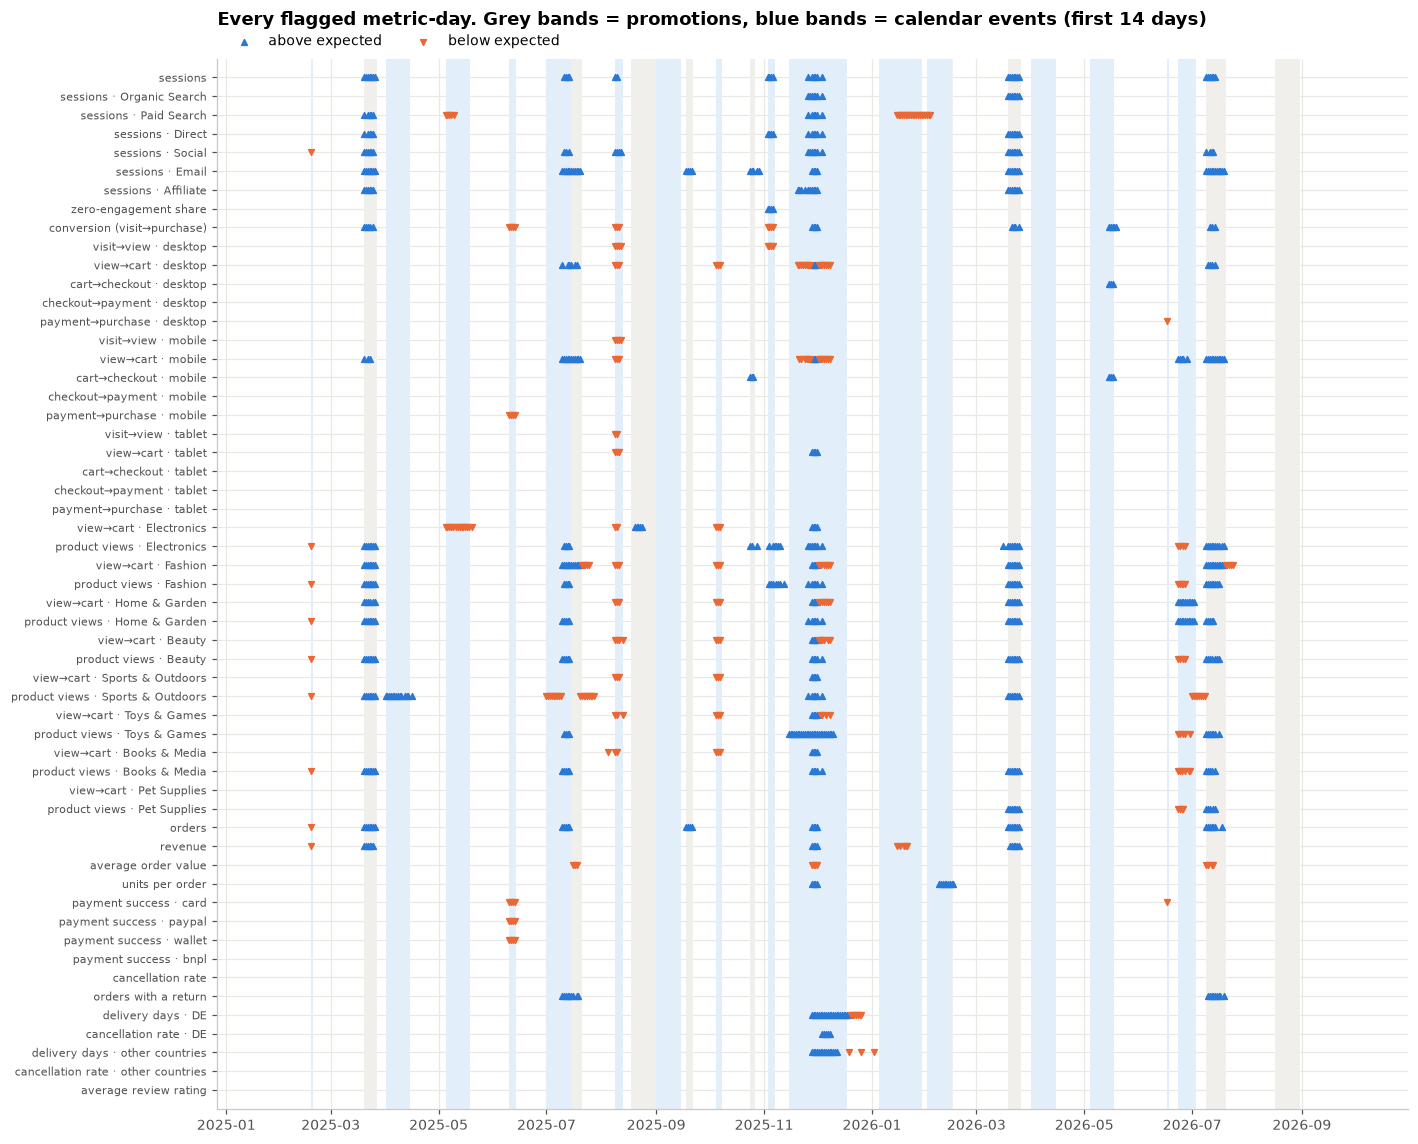

In [6]:
groups_order = ["traffic", "funnel", "category", "sales", "payment", "post-purchase"]
names = [n for g in groups_order for n in M if M[n]["group"] == g]
ypos = {n: i for i, n in enumerate(names[::-1])}
fig, ax = plt.subplots(figsize=(13, 10.5))
for _, c in cal.iterrows():
    if c.kind in ("experiment",):
        continue
    ax.axvspan(DAYS[c.a], DAYS[min(c.b_seen, D - 1)] + pd.Timedelta(days=1), color="#f0efec" if c.kind == "promotion" else "#e3eefb", lw=0)
up, dn = A[A["z"] > 0], A[A["z"] < 0]
ax.scatter(up["date"], up["metric"].map(ypos), s=14, color=BLUE, marker="^", label="above expected", zorder=3)
ax.scatter(dn["date"], dn["metric"].map(ypos), s=14, color=ORANGE, marker="v", label="below expected", zorder=3)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names[::-1], fontsize=7.5)
ax.set_ylim(-1, len(names)); ax.set_xlim(DAYS[FIRST_SCORED], DAYS[-1])
ax.legend(loc="upper left", ncol=2, bbox_to_anchor=(0, 1.035))
ax.set_title("Every flagged metric-day. Grey bands = promotions, blue bands = calendar events (first 14 days)", pad=22)
save(fig, "04_anomaly_map")

## 3. Drill-downs: turning a flag into an explanation
A flag says *something is off*. The explanation comes from asking **which segment carries the deviation** and
**which funnel stage**. Four examples, each ending in a significance test on the isolated effect.

### 3.1 Mobile checkout bug (10–13 Jun 2025)

mobile payment→purchase 82.4% → 47.1% (-43%, z=-35.6, p=1.18e-277); ≈ 862 lost orders ≈ $99,560 in four days


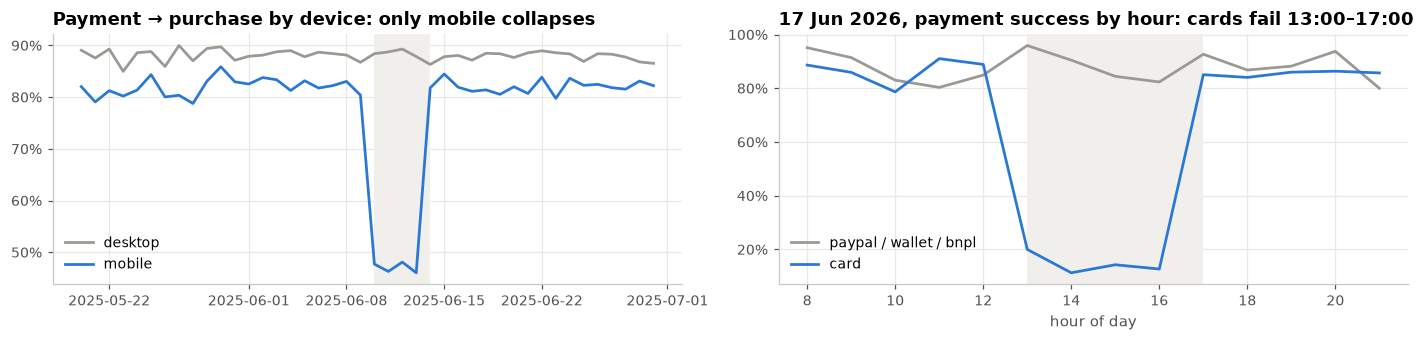

card success rest of day 85.9% vs 13–17h 14.5% (z=-22.2, p=1.21e-109); other methods 86.7% vs 88.2% (p=0.58)
A daily all-method metric dilutes a 4-hour, one-method failure; the per-method panel is what makes it detectable.


In [7]:
def daily_rate(k, n, a, b):
    return pd.Series((k / n)[day_index(a):day_index(b) + 1].values, index=DAYS[day_index(a):day_index(b) + 1])

fig, axes = plt.subplots(1, 2, figsize=(13, 3.2))
for dev, col in (("desktop", GREY), ("mobile", BLUE)):
    axes[0].plot(daily_rate(gd[("purchased", dev)], gd[("entered_payment", dev)], "2025-05-20", "2025-06-30"), color=col, label=dev)
axes[0].axvspan(pd.Timestamp("2025-06-10"), pd.Timestamp("2025-06-14"), color="#f0efec", lw=0)
axes[0].set_title("Payment → purchase by device: only mobile collapses"); axes[0].legend()
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
k0, n0 = gd[("purchased", "mobile")][day_index("2025-05-27"):day_index("2025-06-10")].sum(), gd[("entered_payment", "mobile")][day_index("2025-05-27"):day_index("2025-06-10")].sum()
k1, n1 = gd[("purchased", "mobile")][day_index("2025-06-10"):day_index("2025-06-14")].sum(), gd[("entered_payment", "mobile")][day_index("2025-06-10"):day_index("2025-06-14")].sum()
r = two_prop(k0, n0, k1, n1)
lost = n1 * r["p1"] - k1
aov_m = O.loc[O["device"].eq("mobile") & O["day"].between(day_index("2025-05-27"), day_index("2025-06-09")), "revenue"].mean()
print(f"mobile payment→purchase {r['p1']:.1%} → {r['p2']:.1%} ({r['lift']:+.0%}, z={r['z']:.1f}, p={fmt_p(r['p'])}); "
      f"≈ {lost:,.0f} lost orders ≈ ${lost * aov_m:,.0f} in four days")

# 3.2 payment provider outage, hourly
day = day_index("2026-06-17")
h = S[(S["day"] == day) & S["entered_payment"]].copy()
h["hour"] = h["session_start"].dt.hour
h["card"] = np.where(h["payment_method"].eq("card"), "card", "paypal / wallet / bnpl")
hr = h.groupby(["hour", "card"])["purchased"].agg(["sum", "size"]).unstack()
rate = (hr["sum"] / hr["size"]).loc[8:21]
axes[1].plot(rate.index, rate["paypal / wallet / bnpl"], color=GREY, label="paypal / wallet / bnpl")
axes[1].plot(rate.index, rate["card"], color=BLUE, label="card")
axes[1].axvspan(13, 17, color="#f0efec", lw=0)
axes[1].set_title("17 Jun 2026, payment success by hour: cards fail 13:00–17:00"); axes[1].legend(); axes[1].set_xlabel("hour of day")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
save(fig, "04_drilldown_checkout")
inw = h["hour"].between(13, 16)
tbl = pd.crosstab([h["card"], np.where(inw, "13–17h", "rest of day")], h["purchased"])
c_in, c_out = tbl.loc[("card", "13–17h")], tbl.loc[("card", "rest of day")]
r = two_prop(c_out[True], c_out.sum(), c_in[True], c_in.sum())
o_in, o_out = tbl.loc[("paypal / wallet / bnpl", "13–17h")], tbl.loc[("paypal / wallet / bnpl", "rest of day")]
r2 = two_prop(o_out[True], o_out.sum(), o_in[True], o_in.sum())
print(f"card success rest of day {r['p1']:.1%} vs 13–17h {r['p2']:.1%} (z={r['z']:.1f}, p={fmt_p(r['p'])}); "
      f"other methods {r2['p1']:.1%} vs {r2['p2']:.1%} (p={r2['p']:.2f})")
print("A daily all-method metric dilutes a 4-hour, one-method failure; the per-method panel is what makes it detectable.")

### 3.3 Carrier strike in Germany (Dec 2025) — a post-purchase anomaly
Nothing happens in the on-site funnel; the damage is in delivery times, cancellations, returns and ratings.

In [8]:
w = O["day"].between(day_index("2025-12-04"), day_index("2025-12-19"))
b_ = O["day"].between(day_index("2025-11-06"), day_index("2025-11-26"))
out = []
for lab, cm in (("DE", O["country"].eq("DE")), ("other countries", ~O["country"].eq("DE"))):
    x0, x1 = O[b_ & cm], O[w & cm]
    mw = stats.mannwhitneyu(x1["delivery_days"].dropna().astype(float), x0["delivery_days"].dropna().astype(float))
    cz = two_prop((x0["status"] == "cancelled").sum(), len(x0), (x1["status"] == "cancelled").sum(), len(x1))
    rz = two_prop(x0["status"].isin(["returned", "partially_returned"]).sum(), len(x0), x1["status"].isin(["returned", "partially_returned"]).sum(), len(x1))
    rt_ = stats.ttest_ind(x1["review_rating"].dropna().astype(float), x0["review_rating"].dropna().astype(float), equal_var=False)
    out.append({"country": lab, "delivery days before": x0["delivery_days"].mean(), "during": x1["delivery_days"].mean(), "p (Mann–Whitney)": fmt_p(mw.pvalue),
                "cancel rate before": cz["p1"], "cancel during": cz["p2"], "p (cancel)": fmt_p(cz["p"]),
                "return rate before": rz["p1"], "return during": rz["p2"], "p (return)": fmt_p(rz["p"]),
                "rating before": x0["review_rating"].mean(), "rating during": x1["review_rating"].mean(), "p (rating)": fmt_p(rt_.pvalue)})
strike = pd.DataFrame(out)
strike.to_csv(OUT / "drilldown_carrier_strike.csv", index=False)
display(strike.T)

,0,1
country,DE,other countries
delivery days before,4.1886,4.7314
during,9.7337,5.2894
p (Mann–Whitney),<1e-300,<1e-300
cancel rate before,0.0221,0.0221
cancel during,0.0917,0.0201
p (cancel),1.34e-40,0.1003
return rate before,0.1250,0.1255
return during,0.1502,0.1297
p (return),0.0018,0.1324


### 3.4 Traffic anomalies: viral spike vs bot wave
Both look like "sessions up, conversion down". The difference is in *which* traffic and *what it does*.

In [9]:
def prof(a, b, label):
    m = ca[ca["day"].between(day_index(a), day_index(b))]
    g = m.groupby("channel", observed=True)[["sessions", "bounce0", "viewed_product", "purchased"]].sum()
    return pd.Series({"window": label, "sessions/day": g["sessions"].sum() / (day_index(b) - day_index(a) + 1),
                      "Social share": g.loc["Social", "sessions"] / g["sessions"].sum(), "Direct share": g.loc["Direct", "sessions"] / g["sessions"].sum(),
                      "zero-engagement share": g["bounce0"].sum() / g["sessions"].sum(),
                      "conversion": g["purchased"].sum() / g["sessions"].sum(), "orders/day": g["purchased"].sum() / (day_index(b) - day_index(a) + 1)})
tp = pd.DataFrame([prof("2025-07-26", "2025-08-08", "normal (late Jul 2025)"), prof("2025-08-09", "2025-08-11", "viral spike 9–11 Aug 2025"),
                   prof("2025-10-20", "2025-11-02", "normal (late Oct 2025)"), prof("2025-11-03", "2025-11-06", "bot wave 3–6 Nov 2025")]).set_index("window")
display(tp)
tp.to_csv(OUT / "drilldown_traffic_shocks.csv")

,sessions/day,Social share,Direct share,zero-engagement share,conversion,orders/day
window,,,,,,
normal (late Jul 2025),"27,920.5714",0.1318,0.1783,0.0015,0.0498,"1,391.5000"
viral spike 9–11 Aug 2025,"40,860.3333",0.3888,0.1258,0.0018,0.0359,"1,468.3333"
normal (late Oct 2025),"32,152.0714",0.1372,0.1768,0.0014,0.0497,"1,598.1429"
bot wave 3–6 Nov 2025,"44,741.0000",0.0984,0.4010,0.2761,0.0365,"1,631.2500"


* **Viral spike**: Social share jumps, visitors do view pages (zero-engagement share stays normal) but rarely add to cart.
  Conversion *rate* falls, orders per day do **not** fall. Real people, low intent — no action needed except not to read the
  conversion dip as a site problem.
* **Bot wave**: Direct share jumps, zero-engagement share explodes, orders are unchanged. Not people — filter them out of
  every rate metric (as notebooks 01–03 do).

## 4. Beyond the daily panel
### 4.1 Entity scan: is any single product returning abnormally?
For every product × month with at least 30 delivered order lines, a one-sided binomial test compares its return rate
with its category's rate. That is ~27,000 tests, so p-values are BH-adjusted (false discovery rate 1%).

In [10]:
I["day"] = O["day"].values[I["order_id"].values - 1]
I["cancelled"] = O["status"].eq("cancelled").values[I["order_id"].values - 1]
J = I[~I["cancelled"]].copy()
J["month"] = DAYS[J["day"].values].to_period("M").astype(str)
cat_rate = J.groupby("category", observed=True)["returned"].mean()
pmn = J.groupby(["product_id", "category", "month"], observed=True)["returned"].agg(["sum", "size"]).reset_index()
pmn = pmn[pmn["size"] >= 30].copy()
pmn["category_rate"] = pmn["category"].map(cat_rate).astype(float)
pmn["return_rate"] = pmn["sum"] / pmn["size"]
pmn["p"] = stats.binom.sf(pmn["sum"] - 1, pmn["size"], pmn["category_rate"])
pmn["p_adj"] = bh(pmn["p"])
hits = pmn[pmn["p_adj"] < 0.01].sort_values("p")
hits = hits.merge(P[["product_id", "product_name"]], on="product_id")
print(f"{len(pmn):,} product-months tested; {len(hits)} significant at FDR 1% (a raw p<0.01 rule would have flagged {(pmn['p'] < 0.01).sum()})")
display(hits[["product_name", "category", "month", "size", "sum", "return_rate", "category_rate", "p_adj"]].head(12))
hits.to_csv(OUT / "anomaly_sku_returns.csv", index=False)
truth = (DATA / "ground_truth_notes.txt").read_text()
print("generator ground truth:", [l for l in truth.splitlines() if "defective" in l][0])

10,386 product-months tested; 1 significant at FDR 1% (a raw p<0.01 rule would have flagged 71)


,product_name,category,month,size,sum,return_rate,category_rate,p_adj
0,Electronics-0385,Electronics,2026-02,328,187,0.5701,0.0711,0.0000


generator ground truth: defective_product_id=385


### 4.2 Level shifts
Permanent changes are absorbed by a trailing baseline within a few weeks, so they need a different tool. For a few
structural metrics we scan every candidate date with a two-sample Welch t-test (28 days before vs 28 days after) on
weekday-adjusted values; a peak in |t| marks a level shift, and its location estimates the change date.

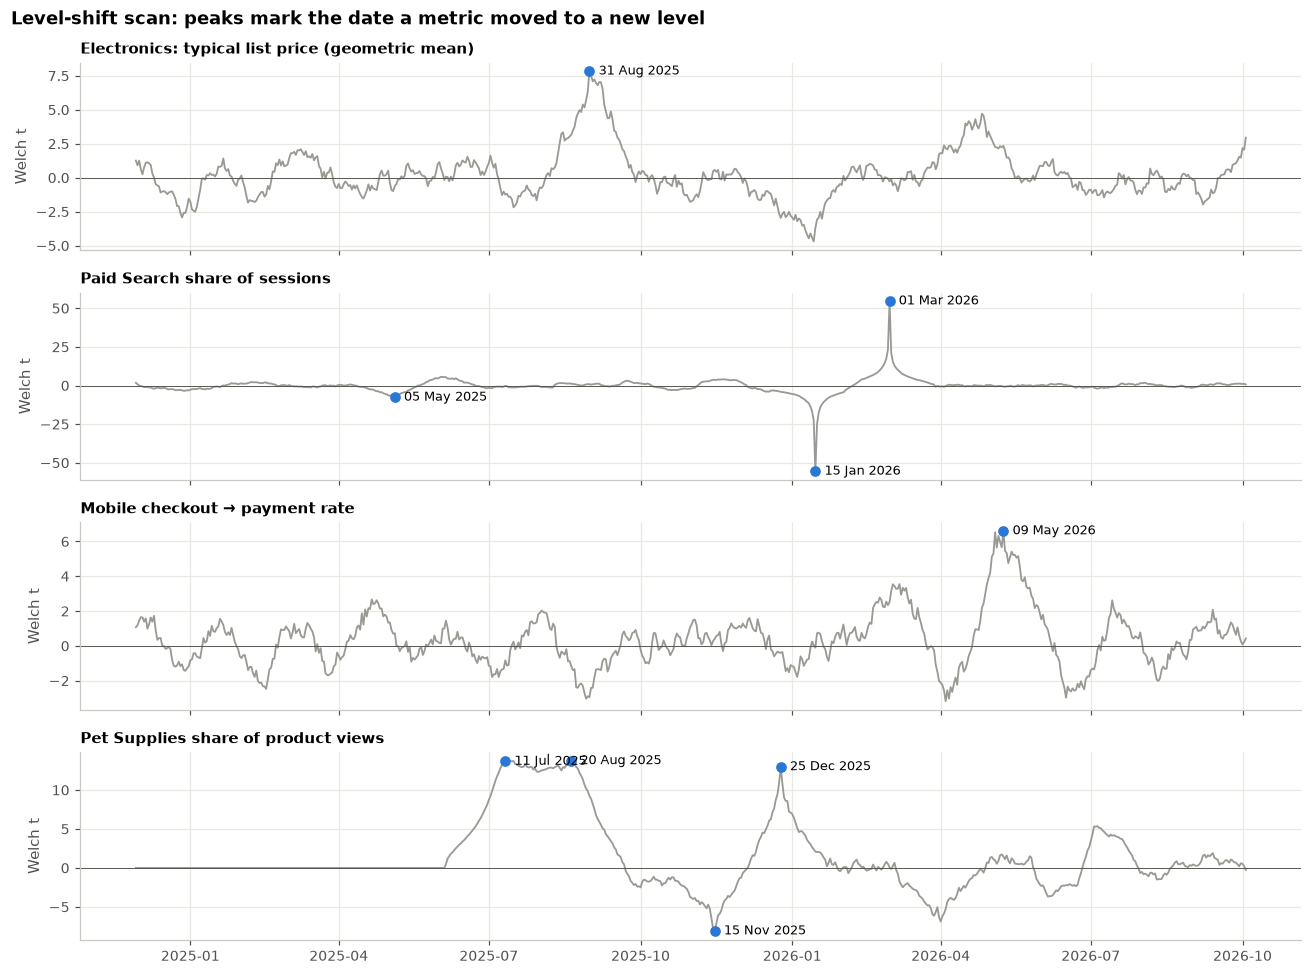

,metric,detected_date,t_stat,before,after,change,calendar
0,Electronics: typical list price (geometric mean),2025-08-31,7.8424,135.5928,147.4599,0.0875,E07 price increase 2025-09-01
1,Paid Search share of sessions,2025-05-05,-7.6233,0.2221,0.2047,-0.0781,E03 competitor campaign from 2025-05-05; E11 budget cut 2026-01-15 → 2026-02-28
2,Paid Search share of sessions,2026-01-15,-55.4821,0.2186,0.1230,-0.4371,E03 competitor campaign from 2025-05-05; E11 budget cut 2026-01-15 → 2026-02-28
3,Paid Search share of sessions,2026-03-01,54.6617,0.1216,0.2189,0.8008,E03 competitor campaign from 2025-05-05; E11 budget cut 2026-01-15 → 2026-02-28
4,Mobile checkout → payment rate,2026-05-09,6.6063,0.7062,0.7288,0.0320,"E14 test start 2026-03-02 (50% of users), E15 rollout 2026-05-04 (100%)"
5,Pet Supplies share of product views,2025-07-11,13.7383,0.0013,0.0195,13.8140,E05 launch 2025-07-01 (60-day ramp); a share also moves when other categories do (toy ...
6,Pet Supplies share of product views,2025-08-20,13.7449,0.0291,0.0479,0.6462,E05 launch 2025-07-01 (60-day ramp); a share also moves when other categories do (toy ...
7,Pet Supplies share of product views,2025-11-15,-8.0974,0.0484,0.0451,-0.0690,E05 launch 2025-07-01 (60-day ramp); a share also moves when other categories do (toy ...
8,Pet Supplies share of product views,2025-12-25,12.9749,0.0452,0.0492,0.0893,E05 launch 2025-07-01 (60-day ramp); a share also moves when other categories do (toy ...


In [11]:
def shift_scan(x, w=28):
    s = pd.Series(np.asarray(x, float))
    s = s - s.groupby(DAYS.dayofweek.values).transform("mean") + s.mean()
    t = np.full(D, np.nan)
    for i in range(w, D - w):
        a, b = s.values[i - w:i], s.values[i:i + w]
        t[i] = (np.nanmean(b) - np.nanmean(a)) / np.sqrt(np.nanvar(a, ddof=1) / w + np.nanvar(b, ddof=1) / w)
    return t

el = np.exp(np.log(I.loc[I["category"].eq("Electronics"), "list_price"]).groupby(I["day"]).mean()).reindex(idx)   # geometric mean
paid_share = ca[ca["channel"].eq("Paid Search")].groupby("day")["sessions"].sum().reindex(idx) / tot["sessions"]
mob_cp = gd[("entered_payment", "mobile")] / gd[("began_checkout", "mobile")]
pet = gc[("viewed_product", "Pet Supplies")] / gc["viewed_product"].sum(axis=1)
series_ = {"Electronics: typical list price (geometric mean)": el, "Paid Search share of sessions": paid_share,
           "Mobile checkout → payment rate": mob_cp, "Pet Supplies share of product views": pet}
fig, axes = plt.subplots(len(series_), 1, figsize=(12, 9), sharex=True)
shifts = []
for ax, (name, x) in zip(axes, series_.items()):
    t = shift_scan(x)
    ax.plot(DAYS, t, color=GREY, lw=1.2)
    ax.axhline(0, color=INK2, lw=0.6)
    tt_ = np.where(np.isnan(t), 0, np.abs(t))
    found = []
    while tt_.max() > 6 and len(found) < 4:
        i = int(tt_.argmax()); found.append(i); tt_[max(i - 35, 0):i + 35] = 0
    for i in sorted(found):
        ax.plot(DAYS[i], t[i], "o", color=BLUE)
        ax.annotate(f"{DAYS[i]:%d %b %Y}", (DAYS[i], t[i]), xytext=(6, 0), textcoords="offset points", fontsize=8.5, va="center")
        before, after = np.nanmean(np.asarray(x, float)[i - 28:i]), np.nanmean(np.asarray(x, float)[i:i + 28])
        shifts.append(dict(metric=name, detected_date=DAYS[i].date(), t_stat=t[i], before=before, after=after, change=after / before - 1))
    ax.set_title(name, fontsize=10); ax.set_ylabel("Welch t")
fig.suptitle("Level-shift scan: peaks mark the date a metric moved to a new level", x=0.01, ha="left", fontweight="bold")
save(fig, "04_level_shifts")
SH = pd.DataFrame(shifts)
truth_dates = {"Electronics: typical list price (geometric mean)": "E07 price increase 2025-09-01",
               "Paid Search share of sessions": "E03 competitor campaign from 2025-05-05; E11 budget cut 2026-01-15 → 2026-02-28",
               "Mobile checkout → payment rate": "E14 test start 2026-03-02 (50% of users), E15 rollout 2026-05-04 (100%)",
               "Pet Supplies share of product views": "E05 launch 2025-07-01 (60-day ramp); a share also moves when other categories do (toy season)"}
SH["calendar"] = SH["metric"].map(truth_dates)
SH.to_csv(OUT / "anomaly_level_shifts.csv", index=False)
display(SH)

## Summary

* A robust same-weekday baseline with MAD scaling, run on ~50 life-cycle metrics, recovers the abrupt planted events —
  incidents, promotions, traffic shocks, external shocks — and the calendar explains nearly all flagged days.
* **Segmentation is what makes anomalies explainable**: the checkout bug is a *mobile × payment-step* anomaly, the provider
  outage a *card × four-hour* anomaly, the strike a *Germany × post-purchase* anomaly, the heatwave a *Home & Garden* one.
  A single blended KPI would have shown most of them as small, ambiguous wobbles.
* **Rate vs volume**: the viral spike and the bot wave both depress the conversion rate without costing a single order.
  Alerting on rates alone produces false alarms; pairing each rate with its numerator avoids them.
* **Multiple testing is the central design constraint**: with tens of thousands of metric-days (and tens of thousands of
  product-months) naive thresholds drown real signals in noise. Thresholds here are set from the number of tests, and the
  entity scan uses FDR control.
* The daily detector is deliberately blind to gradual change and to single-entity problems; the level-shift scan and the
  SKU scan cover those. What none of them can see are balanced experiments — which is exactly why those are analysed as
  experiments (notebook 03) rather than as time series.